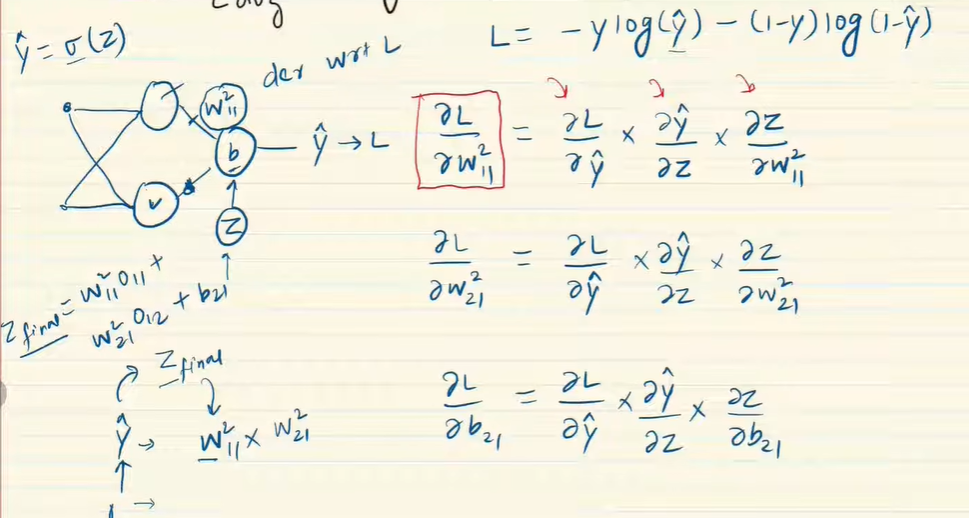
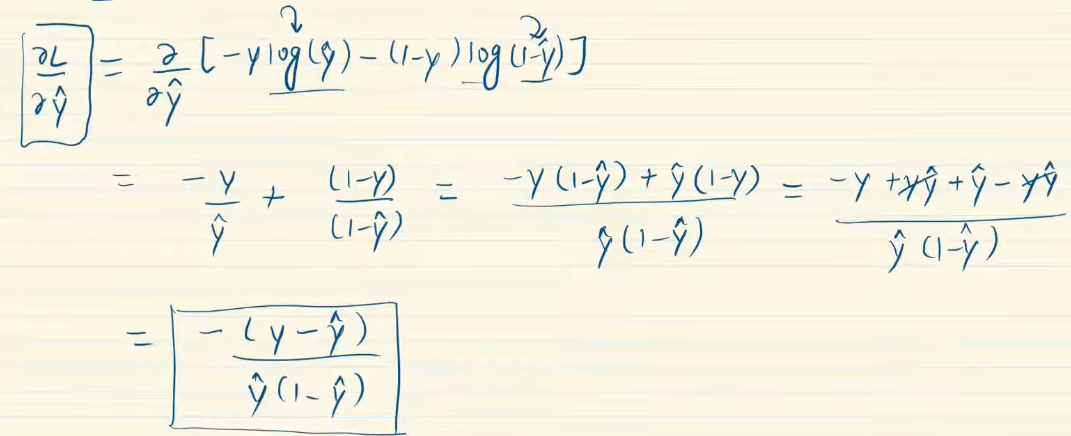
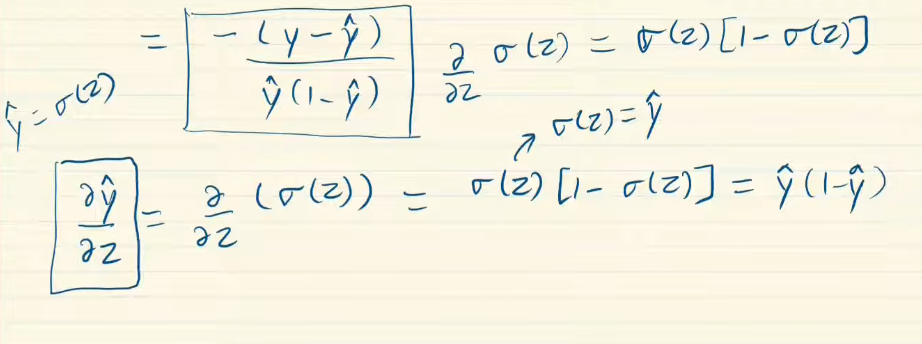
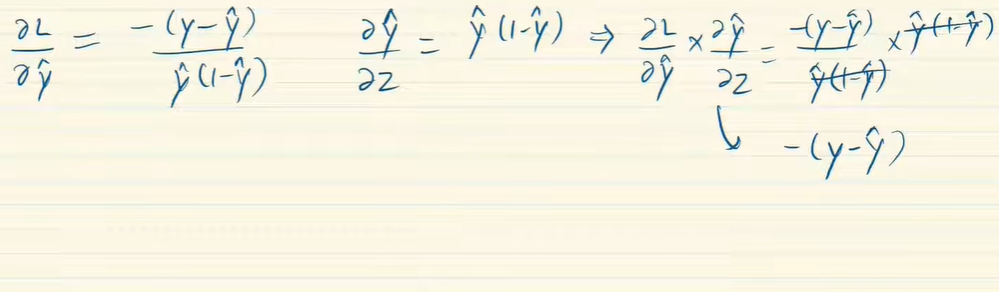
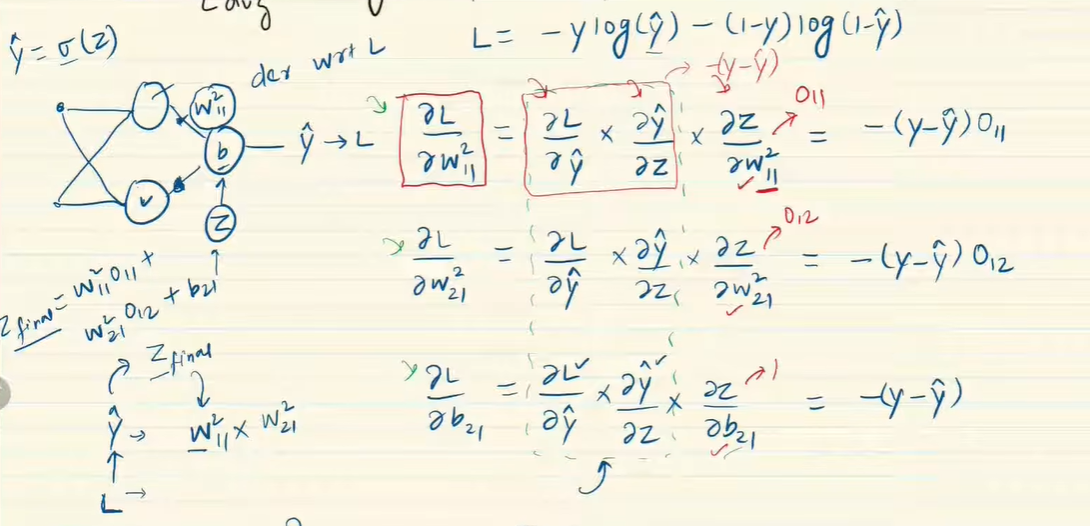

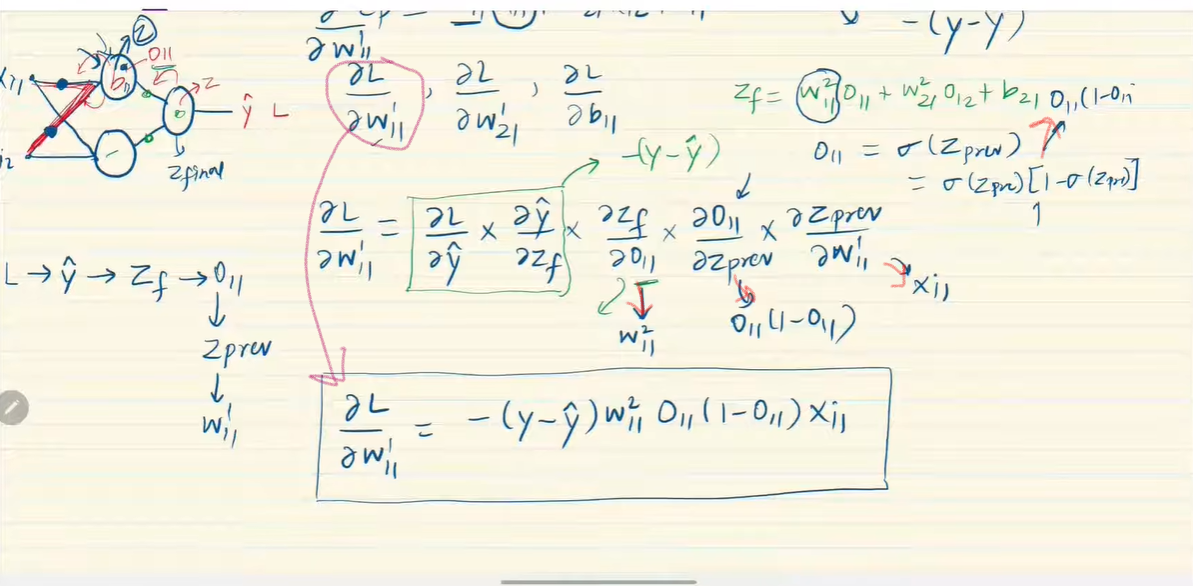
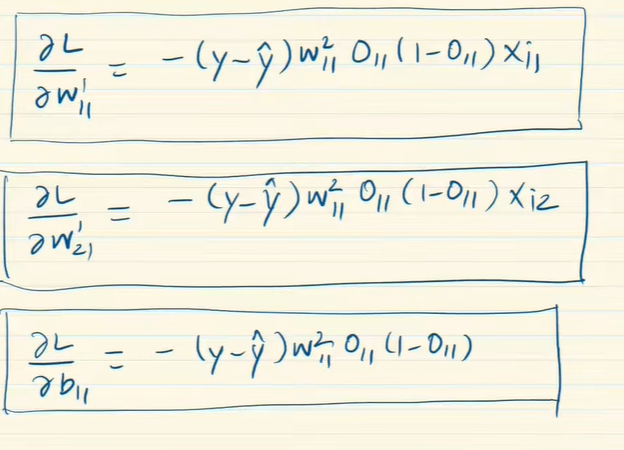
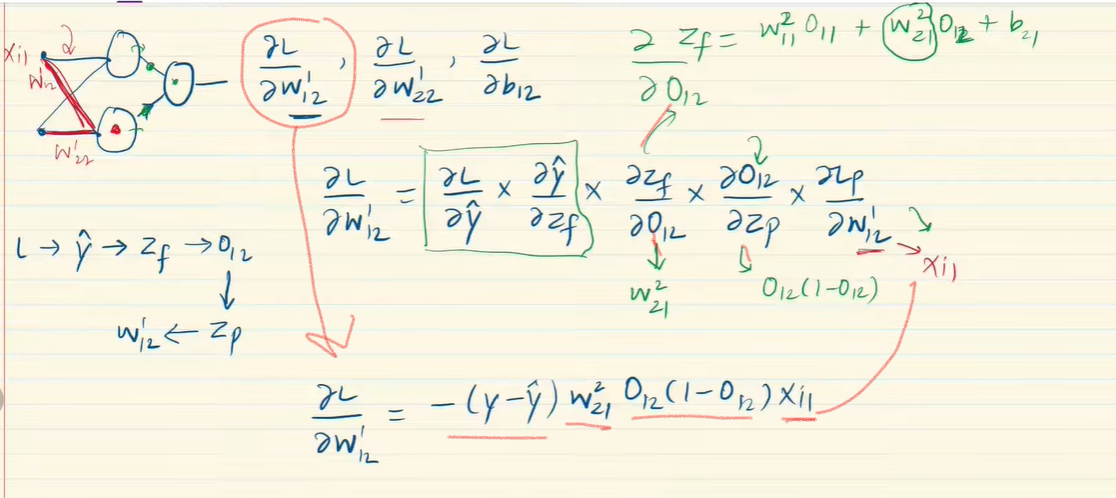
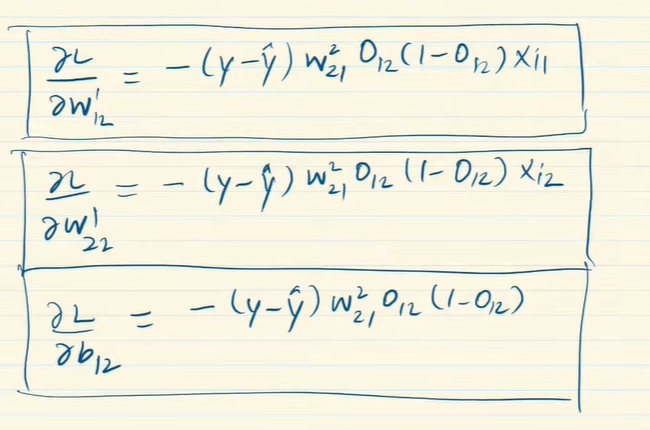

# Backpropagation code implementation for classification

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.DataFrame([[8,8,1],[7,9,1],[6,10,0],[5,12,0]], columns=['cgpa', 'profile_score', 'placed'])

In [3]:
df

,cgpa,profile_score,placed
0,8,8,1
1,7,9,1
2,6,10,0
3,5,12,0


# initialize parameter
- eikhane neural network er architecture initailize korbo
- so, eikhane weight/w = 0.1
- and bias/b = 0

In [4]:
def initialize_parameters(layers_dims):
    
    np.random.seed(3)
    parameters = {}
    L = len(layers_dims)

    for l in range(1,L):
        parameters['W' + str(l)] = np.ones((layers_dims[l-1], layers_dims[l]))*0.1
        parameters['b' + str(l)] = np.zeros((layers_dims[l],1))

    return parameters

# utility function

In [5]:
def sigmoid(Z):
    A = 1/(1 + np.exp(-Z))

    return A

# predict output using forward propagation

In [6]:
def linear_forward(A_prev, W, b):

    Z = np.dot(W.T, A_prev) + b
    A = sigmoid(Z)

    return A

# main forward propagation calculation

In [7]:
# Forward Prop
def L_layer_forward(X, parameters):

  A = X
  A_prev = X
  
  L = len(parameters) // 2                  # number of layers in the neural network
  
  for l in range(1, L+1):

    A_prev = A 
    
    Wl = parameters['W' + str(l)]
    bl = parameters['b' + str(l)]
    # print("A"+str(l-1)+": ", A_prev)
    # print("W"+str(l)+": ", Wl)
    # print("b"+str(l)+": ", bl)
    # print("--"*20)

    A = linear_forward(A_prev, Wl, bl)
    # print("A"+str(l)+": ", A)
    # print("**"*20)
          
  return A , A_prev

# update the parameter using gradient descent mannually

In [9]:
def update_parameters(parameters,y,y_hat,A1,X):
  parameters['W2'][0][0] = parameters['W2'][0][0] + (0.0001 * (y - y_hat)*A1[0][0])
  parameters['W2'][1][0] = parameters['W2'][1][0] + (0.0001 * (y - y_hat)*A1[1][0])
  parameters['b2'][0][0] = parameters['W2'][1][0] + (0.0001 * (y - y_hat))

  parameters['W1'][0][0] = parameters['W1'][0][0] + (0.0001 * (y - y_hat)*parameters['W2'][0][0]*A1[0][0]*(1-A1[0][0])*X[0][0])
  parameters['W1'][0][1] = parameters['W1'][0][1] + (0.0001 * (y - y_hat)*parameters['W2'][0][0]*A1[0][0]*(1-A1[0][0])*X[1][0])
  parameters['b1'][0][0] = parameters['b1'][0][0] + (0.0001 * (y - y_hat)*parameters['W2'][0][0]*A1[0][0]*(1-A1[0][0]))

  parameters['W1'][1][0] = parameters['W1'][1][0] + (0.0001 * (y - y_hat)*parameters['W2'][1][0]*A1[1][0]*(1-A1[1][0])*X[0][0])
  parameters['W1'][1][1] = parameters['W1'][1][1] + (0.0001 * (y - y_hat)*parameters['W2'][1][0]*A1[1][0]*(1-A1[1][0])*X[1][0])
  parameters['b1'][1][0] = parameters['b1'][1][0] + (0.0001 * (y - y_hat)*parameters['W2'][1][0]*A1[1][0]*(1-A1[1][0]))

In [13]:
X = df[['cgpa', 'profile_score']].values[0].reshape(2,1) # Shape(no of features, no. of training example)
y = df[['placed']].values[0][0]

# Parameter initialization
parameters = initialize_parameters([2,2,1])

y_hat,A1 = L_layer_forward(X,parameters)
y_hat = y_hat[0][0]

update_parameters(parameters,y,y_hat,A1,X)

print('Loss for this student - ',-y*np.log(y_hat) - (1-y)*np.log(1-y_hat))

parameters

Loss for this student -  0.613402628898913


{'W1': array([[0.10000513, 0.10000513],
        [0.10000513, 0.10000513]]),
 'b1': array([[6.41054186e-07],
        [6.41054186e-07]]),
 'W2': array([[0.10003815],
        [0.10003815]]),
 'b2': array([[0.100084]])}

In [14]:
X = df[['cgpa', 'profile_score']].values[1].reshape(2,1) # Shape(no of features, no. of training example)
y = df[['placed']].values[1][0]

y_hat,A1 = L_layer_forward(X,parameters)
y_hat = y_hat[0][0]

update_parameters(parameters,y,y_hat,A1,X)

print('Loss for this student - ',-y*np.log(y_hat) - (1-y)*np.log(1-y_hat))

parameters

Loss for this student -  0.568725622654268


{'W1': array([[0.10000937, 0.10001059],
        [0.10000937, 0.10001059]]),
 'b1': array([[1.24770113e-06],
        [1.24770113e-06]]),
 'W2': array([[0.10007424],
        [0.10007424]]),
 'b2': array([[0.10011761]])}

# epochs implementation

In [17]:
# epochs implementation

parameters = initialize_parameters([2,2,1])
epochs = 75

for i in range(epochs):

  Loss = []

  for j in range(df.shape[0]):

    X = df[['cgpa', 'profile_score']].values[j].reshape(2,1) # Shape(no of features, no. of training example)
    y = df[['placed']].values[j][0]

    # Parameter initialization


    y_hat,A1 = L_layer_forward(X,parameters)
    y_hat = y_hat[0][0]

    update_parameters(parameters,y,y_hat,A1,X)

    Loss.append(-y*np.log(y_hat) - (1-y)*np.log(1-y_hat))

  print('Epoch - ',i+1,'Loss - ',np.array(Loss).mean())

parameters

Epoch -  1 Loss -  0.7135494021352312
Epoch -  2 Loss -  0.7023979867791279
Epoch -  3 Loss -  0.702393772800165
Epoch -  4 Loss -  0.7023895608076378
Epoch -  5 Loss -  0.7023853508005624
Epoch -  6 Loss -  0.7023811427779558
Epoch -  7 Loss -  0.7023769367388353
Epoch -  8 Loss -  0.7023727326822189
Epoch -  9 Loss -  0.7023685306071253
Epoch -  10 Loss -  0.7023643305125733
Epoch -  11 Loss -  0.7023601323975824
Epoch -  12 Loss -  0.7023559362611727
Epoch -  13 Loss -  0.7023517421023647
Epoch -  14 Loss -  0.7023475499201793
Epoch -  15 Loss -  0.7023433597136384
Epoch -  16 Loss -  0.7023391714817637
Epoch -  17 Loss -  0.702334985223578
Epoch -  18 Loss -  0.7023308009381042
Epoch -  19 Loss -  0.7023266186243662
Epoch -  20 Loss -  0.7023224382813881
Epoch -  21 Loss -  0.7023182599081943
Epoch -  22 Loss -  0.70231408350381
Epoch -  23 Loss -  0.7023099090672611
Epoch -  24 Loss -  0.7023057365975736
Epoch -  25 Loss -  0.7023015660937743
Epoch -  26 Loss -  0.7022973975548902

{'W1': array([[0.10004999, 0.0995203 ],
        [0.10005005, 0.09951876]]),
 'b1': array([[-2.34205254e-05],
        [-2.35025179e-05]]),
 'W2': array([[0.09830119],
        [0.09830234]]),
 'b2': array([[0.09824576]])}